# EDA de variables externas y su relación con la producción

**Proyecto BCR · Lab 2 · Épica E3 (SCRUM-28)**

Historia de usuario: como equipo de Data Science necesitamos explorar las
variables externas y su relación con la producción para **preseleccionar** las
que entran al modelo. Esta tarea **no** incorpora todavía variables a los
modelos; deja una lista de candidatas con un rezago recomendado.

## Qué hacemos acá

1. Estadística descriptiva y gráficos de cada variable.
2. **Correlación cruzada (CCF)** con la producción para rezagos de **0 a 12
   meses**, sobre **series diferenciadas** (variación mensual en log) para
   evitar correlaciones espurias por tendencia común.
3. Respetamos una **tabla de disponibilidad temporal** al elegir el rezago: de
   nada sirve una correlación en un rezago al que no vamos a tener acceso en el
   momento de pronosticar.

> **Nota de alcance.** Las series de precio están en **pesos nominales**
> (arrastran inflación). Al diferenciar en log se saca la tendencia, y como la
> producción es física (tn / m³, no pesos), la comovimiento inflacionario no
> genera correlación espuria directa. Aun así, para modelar conviene evaluar
> versiones deflactadas. La tabla de disponibilidad es **provisoria**: la
> define SCRUM-26; acá se usa un parámetro editable.

In [1]:
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.stattools import adfuller

warnings.filterwarnings("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
plt.rcParams["axes.grid"] = True

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
DATA = RAIZ / "data"
VEXT = RAIZ / "variables_externas" / "data"
OUT = RAIZ / "results"
OUT.mkdir(exist_ok=True)
print("Raíz:", RAIZ)

Raíz: /home/claude/lab2-bcr


## 1. Carga de datos

### Series objetivo (producción)

Son las cuatro series que hay que pronosticar: biodiesel (tn) y bioetanol
total, de maíz y de caña (m³).

In [2]:
def serie_mensual(df, col):
    s = (df.assign(fecha=pd.to_datetime(df["fecha"]))
           .set_index("fecha")[col].sort_index().astype(float))
    return s[~s.index.duplicated()]

bd = pd.read_csv(DATA / "produccion_biodiesel.csv")
be = pd.read_csv(DATA / "produccion_bioetanol.csv")

objetivos = {
    "biodiesel":       serie_mensual(bd, "produccion_tn"),
    "bioetanol_total": serie_mensual(be, "produccion_total_m3"),
    "bioetanol_maiz":  serie_mensual(be, "produccion_maiz_m3"),
    "bioetanol_cana":  serie_mensual(be, "produccion_cana_m3"),
}
for n, s in objetivos.items():
    print(f"{n:16s}: {s.index.min():%Y-%m} → {s.index.max():%Y-%m}  ({len(s)} meses)")

biodiesel       : 2008-01 → 2026-08  (224 meses)
bioetanol_total : 2009-11 → 2026-08  (202 meses)
bioetanol_maiz  : 2009-11 → 2026-08  (202 meses)
bioetanol_cana  : 2009-11 → 2026-08  (202 meses)


### Variables externas candidatas

Levantamos todo lo que haya disponible. Las de **precio, tipo de cambio y
pizarra** ya están en `data/`. Las de **molienda de soja** y **ventas de
gasoil/nafta** las genera el relevamiento de SCRUM-25 en
`variables_externas/data/` (hay que correr sus scrapers una vez). Si algún
archivo falta, se omite y el resto del análisis corre igual.

In [3]:
# Cada entrada: (archivo, columna, nombre_legible, carpeta)
fuentes = [
    (DATA / "tipo_cambio_mensual.csv",    "tc_promedio_mes",            "tipo_cambio"),
    (DATA / "soja_maiz_cac_mensual.csv",  "soja_ars_tn",               "precio_soja_pizarra"),
    (DATA / "soja_maiz_cac_mensual.csv",  "maiz_ars_tn",               "precio_maiz_pizarra"),
    (DATA / "biodiesel_precios.csv",      "precio_ars_tn",             "precio_biodiesel"),
    (DATA / "bioetanol_precios.csv",      "precio_cana_ars_l",         "precio_bioetanol_cana"),
    (DATA / "bioetanol_precios.csv",      "precio_maiz_ars_l",         "precio_bioetanol_maiz"),
    (VEXT / "soja_mensual.csv",           "molienda_soja_tn",          "molienda_soja"),
    (VEXT / "combustibles_mensual.csv",   "ventas_gasoil_grados1a3_m3","ventas_gasoil"),
    (VEXT / "combustibles_mensual.csv",   "ventas_nafta_grados1a3_m3", "ventas_nafta"),
]

externas = {}
faltantes = []
for archivo, col, nombre in fuentes:
    if archivo.exists():
        externas[nombre] = serie_mensual(pd.read_csv(archivo), col)
    else:
        faltantes.append(f"{nombre} ({archivo.name})")

print("Variables externas cargadas:")
for n, s in externas.items():
    print(f"  {n:22s}: {s.index.min():%Y-%m} → {s.index.max():%Y-%m}  ({len(s)} meses)")
if faltantes:
    print("\nFALTAN (corré los scrapers de variables_externas/):")
    for f in faltantes:
        print("  -", f)

Variables externas cargadas:
  tipo_cambio           : 2018-01 → 2026-09  (105 meses)
  precio_soja_pizarra   : 2018-01 → 2026-09  (105 meses)
  precio_maiz_pizarra   : 2018-01 → 2026-09  (105 meses)
  precio_biodiesel      : 2018-01 → 2026-09  (77 meses)
  precio_bioetanol_cana : 2018-06 → 2026-09  (59 meses)
  precio_bioetanol_maiz : 2018-06 → 2026-09  (59 meses)
  molienda_soja         : 2015-01 → 2026-08  (140 meses)
  ventas_gasoil         : 2010-01 → 2026-08  (200 meses)
  ventas_nafta          : 2010-01 → 2026-08  (200 meses)


## 2. Estadística descriptiva

Resumen numérico de cada variable (nivel). Las escalas son muy distintas
(toneladas, m³, $/tn, $/l, $/USD), así que acá solo miramos cada una en sus
propias unidades.

In [4]:
desc = pd.DataFrame({n: s.describe() for n, s in {**objetivos, **externas}.items()}).T
desc = desc[["count", "mean", "std", "min", "50%", "max"]].rename(columns={"50%": "mediana"})
desc.round(1)

,count,mean,std,min,mediana,max
biodiesel,224.0,150100.0,71069.3,9058.4,142499.0,308897.0
bioetanol_total,202.0,70378.7,34984.1,771.0,76818.0,139521.0
bioetanol_maiz,202.0,38129.7,22879.2,0.0,44098.8,74649.6
bioetanol_cana,202.0,32249.0,16451.5,268.2,30584.2,67782.6
tipo_cambio,105.0,447.1,522.5,19.0,117.8,1510.6
precio_soja_pizarra,105.0,145532.4,166732.7,5133.6,49359.7,558500.0
precio_maiz_pizarra,105.0,83609.2,95269.6,2878.4,30302.4,291464.0
precio_biodiesel,77.0,583161.7,668601.5,15447.0,185785.0,2012598.0
precio_bioetanol_cana,59.0,392.9,402.7,18.0,88.2,1072.5
precio_bioetanol_maiz,59.0,364.0,366.8,15.2,107.4,983.0


### Gráficos de nivel

Cada variable en el tiempo. Sirve para ver tendencia, estacionalidad y saltos
(p. ej. el desplome de molienda de dic-2020, la caída de ventas en la cuarentena
de 2020, o los saltos escalonados de los precios regulados por inflación).

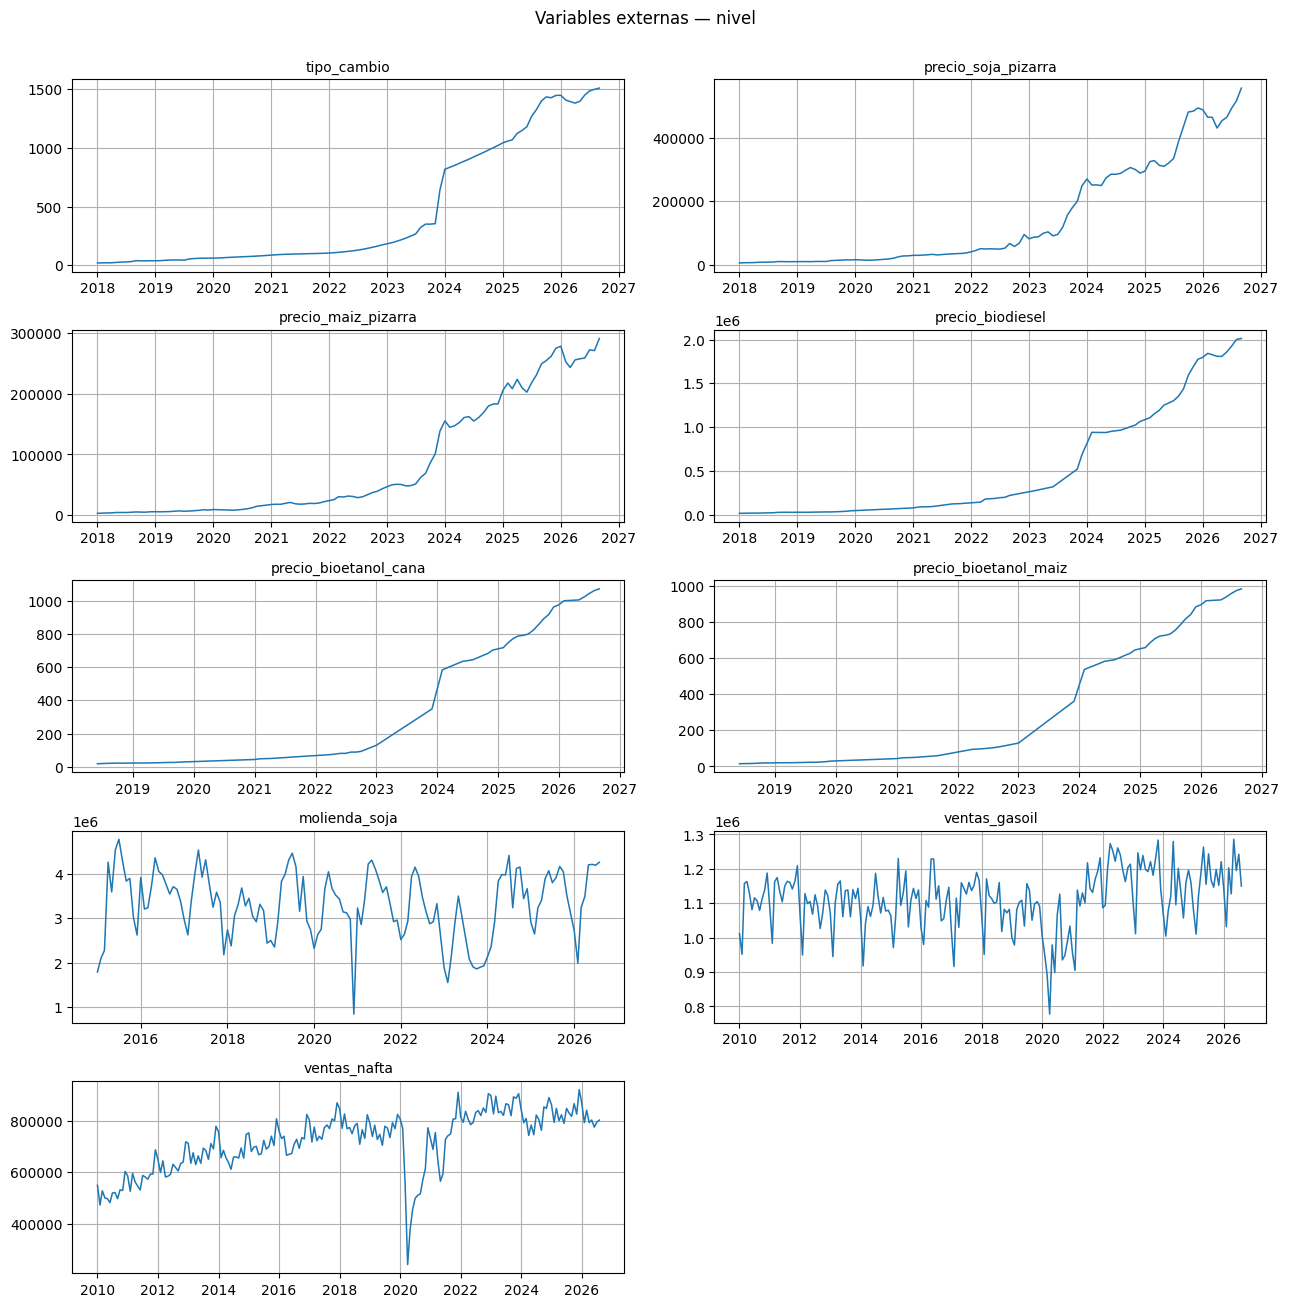

In [5]:
items = list(externas.items())
filas = (len(items) + 1) // 2
fig, axes = plt.subplots(filas, 2, figsize=(13, 2.6 * filas))
for ax, (nombre, s) in zip(axes.ravel(), items):
    ax.plot(s.index, s.values, lw=1.1)
    ax.set_title(nombre, fontsize=10)
for ax in axes.ravel()[len(items):]:
    ax.axis("off")
fig.suptitle("Variables externas — nivel", y=1.002, fontsize=12)
fig.tight_layout(); plt.show()

## 3. ¿Por qué diferenciar? Estacionariedad (ADF)

Casi todas las series tienen tendencia (sobre todo las de precio, por
inflación). Correlacionar series con tendencia da correlaciones **espurias**:
dos cosas que suben juntas "correlacionan" aunque no tengan relación.

La solución estándar es trabajar sobre la **variación mensual en log**
(`Δ log x = log(x_t) − log(x_{t-1})`), que quita la tendencia y deja la señal
de corto plazo. El test ADF confirma: en nivel no se rechaza la raíz unitaria
(no estacionaria), diferenciada sí.

In [6]:
def adf_p(s):
    s = s.dropna()
    if (s <= 0).any():
        return np.nan, np.nan
    nivel = adfuller(s)[1]
    dif = adfuller(np.log(s).diff().dropna())[1]
    return nivel, dif

filas = []
for n, s in {**objetivos, **externas}.items():
    pn, pd_ = adf_p(s)
    filas.append({"variable": n, "p_ADF_nivel": pn, "p_ADF_logdiff": pd_,
                  "nivel_estacionario": pn < 0.05 if pn == pn else None,
                  "logdiff_estacionario": pd_ < 0.05 if pd_ == pd_ else None})
tabla_adf = pd.DataFrame(filas).set_index("variable")
print("p<0.05 ⇒ estacionaria. Esperamos: nivel NO, log-diff SÍ.")
tabla_adf.round(3)

p<0.05 ⇒ estacionaria. Esperamos: nivel NO, log-diff SÍ.


,p_ADF_nivel,p_ADF_logdiff,nivel_estacionario,logdiff_estacionario
variable,,,,
biodiesel,0.251,0.000,False,True
bioetanol_total,0.506,0.076,False,False
bioetanol_maiz,NaN,NaN,None,None
bioetanol_cana,0.214,0.000,False,True
tipo_cambio,0.993,0.000,False,True
precio_soja_pizarra,1.000,0.000,False,True
precio_maiz_pizarra,0.999,0.000,False,True
precio_biodiesel,0.998,0.000,False,True
precio_bioetanol_cana,0.980,0.000,False,True


Trabajamos entonces sobre `Δ log` de cada serie (tanto la producción como las
externas). Para la producción esto coincide con la **variación mensual** que ya
usa el EDA de producción y con lo que publica la BCR en el IACA.

In [7]:
def logdiff(s):
    s = s.dropna()
    s = s[s > 0]
    return np.log(s).diff().dropna()

obj_d = {n: logdiff(s) for n, s in objetivos.items()}
ext_d = {n: logdiff(s) for n, s in externas.items()}

## 4. Correlación cruzada (CCF) con la producción

Para cada par (variable externa, producción) calculamos la correlación entre
`x` rezagada `k` meses y la producción, para `k = 0 … 12`:

$$\rho_k = \mathrm{corr}\big(x_{t-k},\; y_t\big)$$

Un `k` positivo significa que la variable externa **adelanta** a la producción
en `k` meses (es un indicador líder). Eso es justo lo que sirve para
pronosticar: si `x` de hace `k` meses anticipa la producción de hoy, y ese dato
está disponible a tiempo, es una candidata.

**Significancia:** bandas aproximadas de ±1,96/√n (95%). Una correlación que
cae dentro de la banda no se distingue de ruido.

In [8]:
MAX_LAG = 12

def ccf_series(x, y, max_lag=MAX_LAG):
    """corr(x[t-k], y[t]) para k=0..max_lag, sobre índices comunes."""
    out = {}
    for k in range(max_lag + 1):
        xk = x.shift(k)
        df = pd.concat([xk, y], axis=1, join="inner").dropna()
        out[k] = (df.iloc[:, 0].corr(df.iloc[:, 1]), len(df))
    return out

def tabla_ccf(target_d, ext_d):
    corr, n = {}, {}
    for nombre, x in ext_d.items():
        res = ccf_series(x, target_d)
        corr[nombre] = {k: v[0] for k, v in res.items()}
        n[nombre] = {k: v[1] for k, v in res.items()}
    return pd.DataFrame(corr).T, pd.DataFrame(n).T

print("CCF lista. Convención: rezago k>0 ⇒ la variable externa adelanta a la producción.")

CCF lista. Convención: rezago k>0 ⇒ la variable externa adelanta a la producción.


### Heatmaps de CCF por serie objetivo

Una grilla por cada producción: filas = variables externas, columnas = rezago
(0 a 12). Rojo = correlación positiva, azul = negativa. Marcamos con un punto
las celdas **significativas** (fuera de la banda de ±1,96/√n).

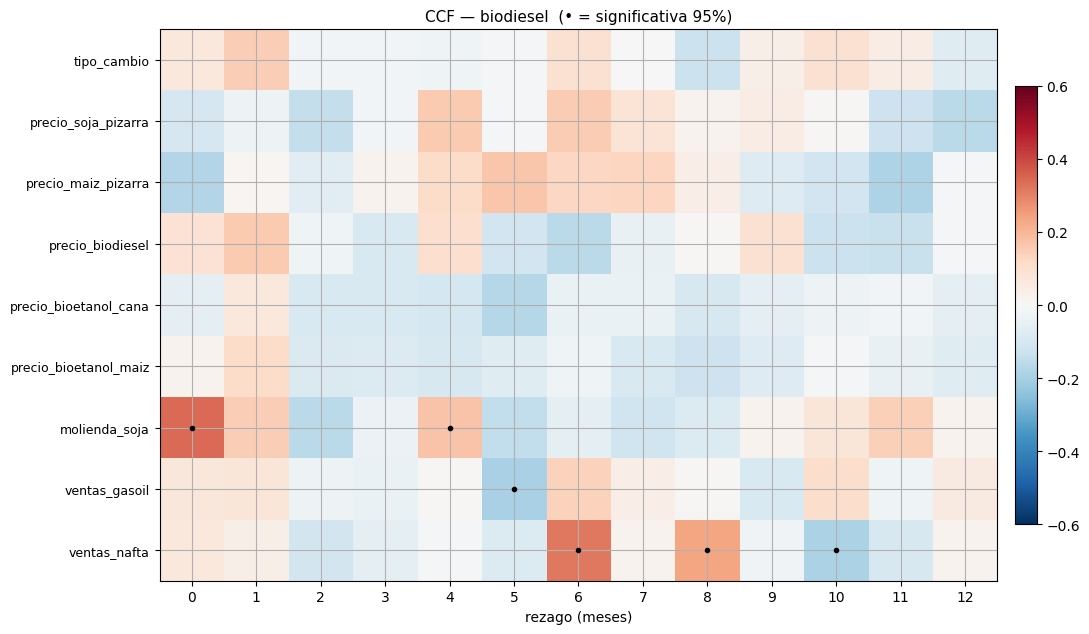

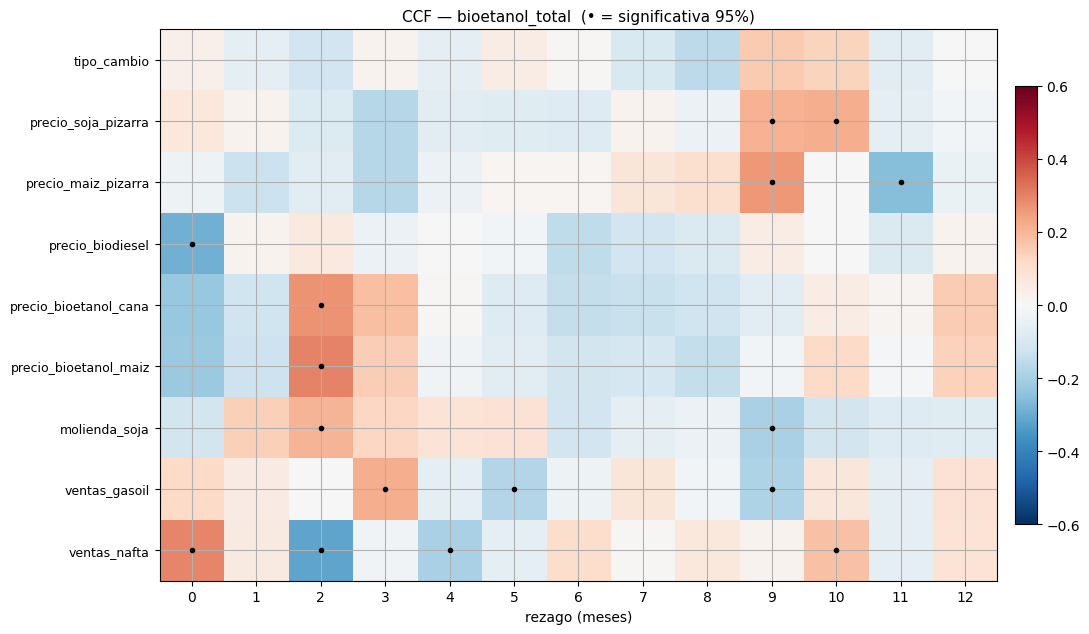

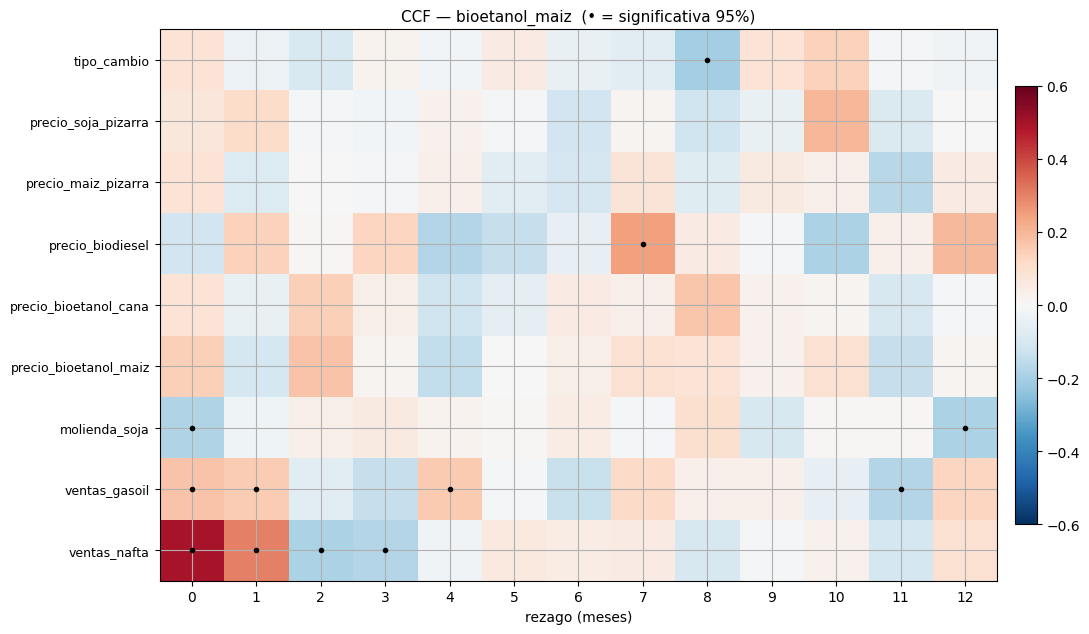

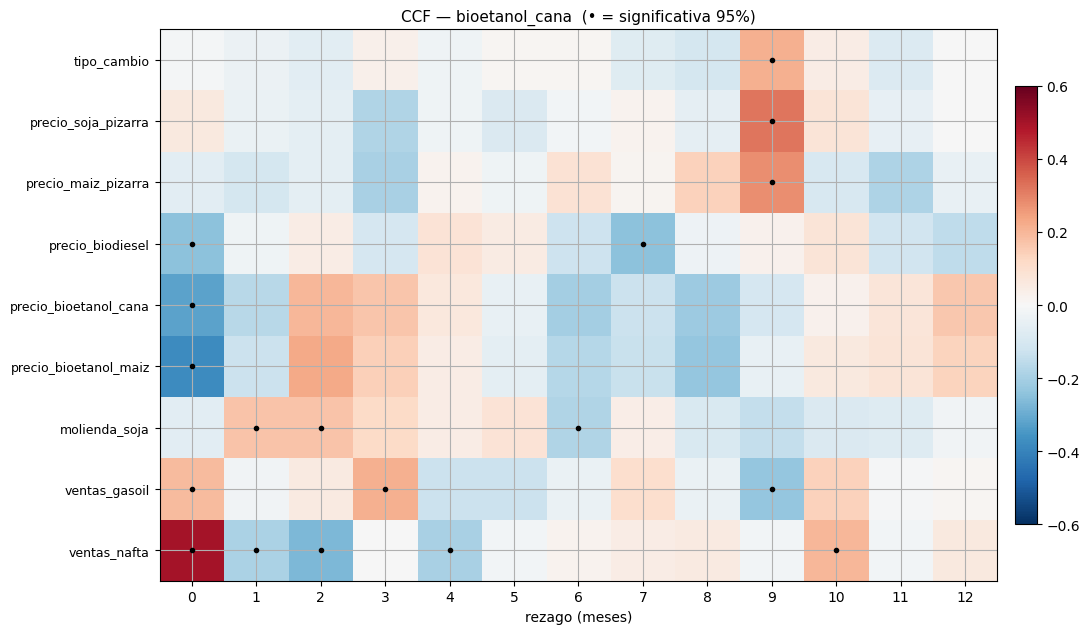

In [9]:
def heatmap_ccf(nombre_target, target_d):
    corr, n = tabla_ccf(target_d, ext_d)
    banda = 1.96 / np.sqrt(n.replace(0, np.nan))
    sig = corr.abs() > banda
    fig, ax = plt.subplots(figsize=(11, 0.55 * len(corr) + 1.5))
    im = ax.imshow(corr.values, cmap="RdBu_r", vmin=-0.6, vmax=0.6, aspect="auto")
    ax.set_xticks(range(MAX_LAG + 1)); ax.set_xticklabels(range(MAX_LAG + 1))
    ax.set_yticks(range(len(corr))); ax.set_yticklabels(corr.index, fontsize=9)
    ax.set_xlabel("rezago (meses)")
    for i in range(len(corr)):
        for j in range(MAX_LAG + 1):
            if bool(sig.values[i, j]):
                ax.plot(j, i, "o", ms=3, color="black")
    ax.set_title(f"CCF — {nombre_target}  (• = significativa 95%)", fontsize=11)
    fig.colorbar(im, ax=ax, fraction=0.025, pad=0.02)
    fig.tight_layout(); plt.show()
    return corr, n

ccf_tablas = {}
for nombre, td in obj_d.items():
    ccf_tablas[nombre] = heatmap_ccf(nombre, td)

## 5. Disponibilidad temporal y selección de candidatas

El rezago recomendado no puede ser cualquiera: tiene que ser uno al que
**vayamos a tener acceso** cuando pronostiquemos. Para un pronóstico a un mes,
al estimar la producción del mes `t` (que la Secretaría publica con ~2 meses de
atraso), ya tenemos la variable externa hasta cierto mes según su propio
calendario de publicación.

Codificamos un **rezago mínimo disponible** por variable. Es **provisorio**: lo
define SCRUM-26. Acá va un valor conservador y editable.

In [10]:
# Rezago MÍNIMO utilizable por variable (meses). PROVISORIO — lo fija SCRUM-26.
#  0 = el dato del propio mes ya está disponible al pronosticar.
#  1 = recién está disponible el dato del mes anterior, etc.
rezago_min = {
    "tipo_cambio":            0,   # BCRA, inmediato
    "precio_soja_pizarra":    0,   # CAC, diario
    "precio_maiz_pizarra":    0,   # CAC, diario
    "precio_biodiesel":       0,   # SE, precio regulado del mes
    "precio_bioetanol_cana":  0,
    "precio_bioetanol_maiz":  0,
    "ventas_gasoil":          1,   # SESCO, ~1-2 meses de atraso
    "ventas_nafta":           1,
    "molienda_soja":          1,   # SAGyP, ~1-2 meses de atraso
}
DEFAULT_MIN = 1  # para cualquier variable no listada

def seleccionar(nombre_target):
    corr, n = ccf_tablas[nombre_target]
    banda = 1.96 / np.sqrt(n.replace(0, np.nan))
    filas = []
    for var in corr.index:
        fila = corr.loc[var]
        kmin = rezago_min.get(var, DEFAULT_MIN)
        disponibles = fila.loc[kmin:]
        # mejor rezago GLOBAL (cualquier k) y mejor DISPONIBLE (k>=kmin)
        kg = fila.abs().idxmax()
        kd = disponibles.abs().idxmax()
        sig_d = abs(disponibles[kd]) > banda.loc[var, kd]
        filas.append({
            "target": nombre_target, "variable": var,
            "rezago_min_disp": kmin,
            "mejor_rezago_disp": int(kd), "corr_disp": round(float(fila[kd]), 3),
            "signif_disp": bool(sig_d),
            "mejor_rezago_global": int(kg), "corr_global": round(float(fila[kg]), 3),
            "n_obs": int(n.loc[var, kd]),
            "candidata": bool(sig_d),
        })
    return pd.DataFrame(filas)

candidatas = pd.concat([seleccionar(t) for t in obj_d], ignore_index=True)
candidatas = candidatas.sort_values(["target", "signif_disp", "corr_disp"],
                                    ascending=[True, False, False],
                                    key=lambda c: c.abs() if c.name == "corr_disp" else c)
candidatas.to_csv(OUT / "variables_candidatas.csv", index=False)
print("Guardado:", OUT / "variables_candidatas.csv")
candidatas

Guardado: /home/claude/lab2-bcr/results/variables_candidatas.csv


,target,variable,rezago_min_disp,mejor_rezago_disp,corr_disp,signif_disp,mejor_rezago_global,corr_global,n_obs,candidata
8,biodiesel,ventas_nafta,1,6,0.315,True,6,0.315,193,True
7,biodiesel,ventas_gasoil,1,5,-0.196,True,5,-0.196,194,True
6,biodiesel,molienda_soja,1,4,0.172,True,0,0.338,135,True
2,biodiesel,precio_maiz_pizarra,0,11,-0.185,False,11,-0.185,92,False
4,biodiesel,precio_bioetanol_cana,0,5,-0.171,False,5,-0.171,52,False
1,biodiesel,precio_soja_pizarra,0,12,-0.162,False,12,-0.162,91,False
3,biodiesel,precio_biodiesel,0,6,-0.159,False,6,-0.159,69,False
0,biodiesel,tipo_cambio,0,1,0.148,False,1,0.148,102,False
5,biodiesel,precio_bioetanol_maiz,0,8,-0.123,False,8,-0.123,49,False
32,bioetanol_cana,precio_bioetanol_maiz,0,0,-0.375,True,0,-0.375,57,True


### Lista final de candidatas por serie

Nos quedamos con las que tienen una correlación **significativa** en un rezago
**disponible**. Ese es el entregable del DoD: variables candidatas con su
rezago recomendado.

In [11]:
for t in obj_d:
    sub = candidatas[(candidatas.target == t) & candidatas.candidata]
    print(f"\n### {t}")
    if sub.empty:
        print("  (sin candidatas significativas en rezagos disponibles)")
        continue
    for _, r in sub.iterrows():
        signo = "+" if r.corr_disp > 0 else "−"
        print(f"  {r.variable:22s}  rezago {r.mejor_rezago_disp:>2} meses  "
              f"corr {signo}{abs(r.corr_disp):.2f}  (n={r.n_obs})")


### biodiesel
  ventas_nafta            rezago  6 meses  corr +0.32  (n=193)
  ventas_gasoil           rezago  5 meses  corr −0.20  (n=194)
  molienda_soja           rezago  4 meses  corr +0.17  (n=135)

### bioetanol_total
  ventas_nafta            rezago  2 meses  corr −0.32  (n=197)
  precio_bioetanol_maiz   rezago  2 meses  corr +0.30  (n=55)
  precio_biodiesel        rezago  0 meses  corr −0.29  (n=75)
  precio_bioetanol_cana   rezago  2 meses  corr +0.27  (n=55)
  precio_maiz_pizarra     rezago  9 meses  corr +0.26  (n=94)
  precio_soja_pizarra     rezago 10 meses  corr +0.22  (n=93)
  ventas_gasoil           rezago  3 meses  corr +0.22  (n=196)
  molienda_soja           rezago  2 meses  corr +0.20  (n=137)

### bioetanol_maiz
  ventas_nafta            rezago  1 meses  corr +0.30  (n=167)
  precio_biodiesel        rezago  7 meses  corr +0.25  (n=68)
  tipo_cambio             rezago  8 meses  corr −0.20  (n=95)
  molienda_soja           rezago 12 meses  corr −0.19  (n=127)
  vent

## 6. Conclusiones y próximos pasos

- La **lista de candidatas con rezago recomendado** queda en
  `results/variables_candidatas.csv` (una fila por par variable–serie).
- El criterio fue: correlación cruzada **significativa** (95%) en un rezago
  **disponible** según la tabla de disponibilidad temporal.
- La tabla de disponibilidad (`rezago_min`) es **provisoria**: la cierra
  SCRUM-26. Si cambia el rezago mínimo de una variable, se recalcula la
  selección sin tocar nada más.

**Para el modelado (SCRUM-24 en adelante):**

1. Entran al modelo las candidatas de cada serie, cada una en **su** rezago
   recomendado (nunca en un rezago no disponible → evita fuga de información
   futura en el walk-forward).
2. Las variables de **precio** están en pesos nominales; probar versiones
   deflactadas antes de descartarlas por ruido.
3. Correlación ≠ causalidad ni ≠ mejora predictiva: la preselección reduce el
   espacio de búsqueda, pero el aporte real de cada variable se mide con el
   **mismo protocolo** (`evaluacion.py`) comparando el modelo con y sin ella.